Computational exercises - Set 5 - All
Ali khabazian - 402416066

Q1

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Bifurcation Diagram')

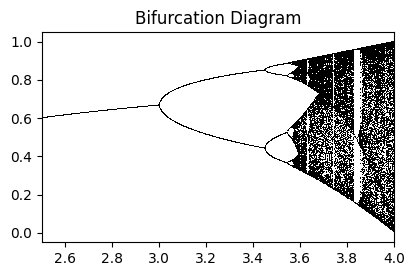

In [2]:
def logistic_map(r, x0, n):
    x = np.zeros(n)
    x[0] = x0
    for i in range(1, n):
        x[i] = r * x[i-1] * (1 - x[i-1])
    return x

r_values = np.linspace(2.5, 4, 1000)
x0 = 0.5
n = 1000
bifurcation = []
for r in r_values:
    x = logistic_map(r, x0, n)
    bifurcation.append(x[-100:])

plt.figure(figsize=(10, 6))
plt.subplot(2, 2, 1)
plt.plot(r_values, bifurcation, ',k', ms=0.1)
plt.xlim(2.5, 4)
plt.title('Bifurcation Diagram')

Text(0.5, 1.0, 'One-cycle (r = 3.2)')

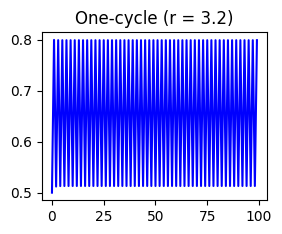

In [3]:
r = 3.2
x0 = 0.5
n = 100
one_cycle = logistic_map(r, x0, n)
plt.subplot(2, 2, 2)
plt.plot(range(n), one_cycle, 'b-')
plt.title('One-cycle (r = 3.2)')

Text(0.5, 1.0, 'Two-cycle (r = 3.5)')

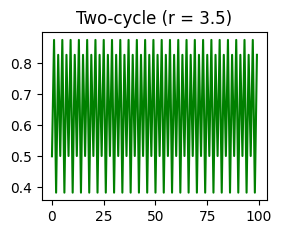

In [4]:
r = 3.5
x0 = 0.5
n = 100
two_cycle = logistic_map(r, x0, n)
plt.subplot(2, 2, 3)
plt.plot(range(n), two_cycle, 'g-')
plt.title('Two-cycle (r = 3.5)')

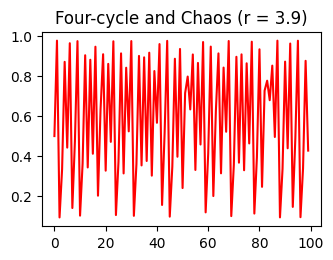

In [5]:
r = 3.9
x0 = 0.5
n = 100
four_cycle = logistic_map(r, x0, n)
plt.subplot(2, 2, 4)
plt.plot(range(n), four_cycle, 'r-')
plt.title('Four-cycle and Chaos (r = 3.9)')

plt.tight_layout()
plt.show()

Q2

In [6]:
from scipy.integrate import odeint

In [7]:
w_0 = 1.0
alpha = 0.2
w = 0.666
f = 0.52

def chaotic_oscillator(state, t, f):
    theta, dtheta_dt = state
    d2theta_dt2 = -w_0**2 * np.sin(theta) - alpha * dtheta_dt + f * np.cos(w * t)
    return [dtheta_dt, d2theta_dt2]


theta_0 = np.pi / 2
dtheta_dt_0 = 0.0
state_0 = [theta_0, dtheta_dt_0]

t_span = np.linspace(0, 200, 10000)


solution = odeint(chaotic_oscillator, state_0, t_span, args=(f,))
theta = solution[:, 0]
dtheta_dt = solution[:, 1]

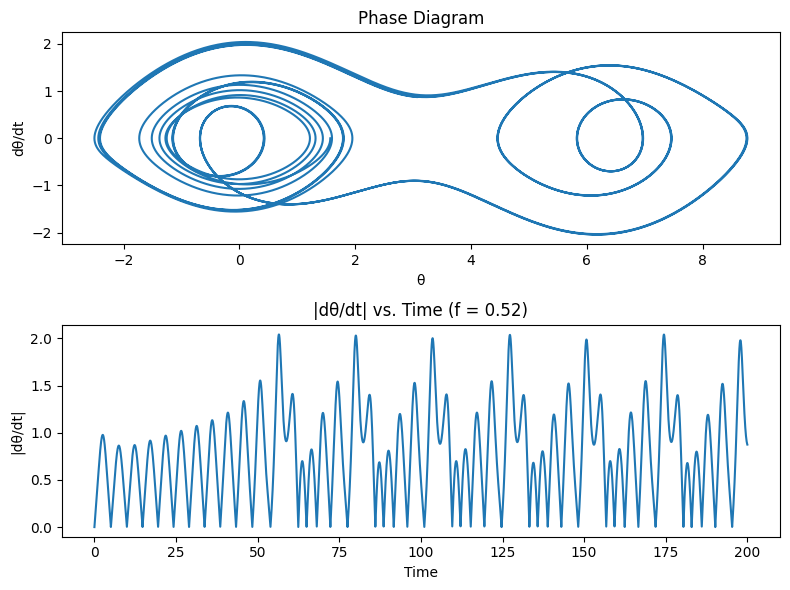

In [8]:
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.plot(theta, dtheta_dt)
plt.xlabel('θ')
plt.ylabel('dθ/dt')
plt.title('Phase Diagram')

plt.subplot(2, 1, 2)
plt.plot(t_span, np.abs(dtheta_dt))
plt.xlabel('Time')
plt.ylabel('|dθ/dt|')
plt.title('|dθ/dt| vs. Time (f = {:.2f})'.format(f))

plt.tight_layout()
plt.show()

Q3

In [12]:
def lorenz_equations(state, t, sigma=10, beta=8/3, rho=28):
    x, y, z = state
    dx_dt = sigma * (y - x)
    dy_dt = x * (rho - z) - y
    dz_dt = x * y - beta * z
    return [dx_dt, dy_dt, dz_dt]

x0, y0, z0 = 1, 1, 1
state0 = [x0, y0, z0]

t_span = np.linspace(0, 50, 10000)

solution = odeint(lorenz_equations, state0, t_span)
x, y, z = solution.T

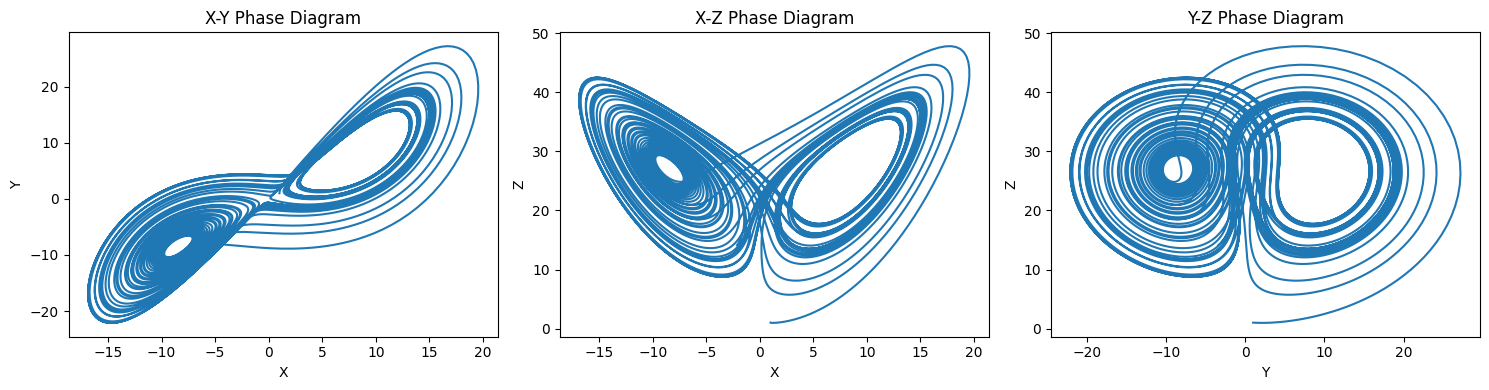

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# X-Y phase diagram
axes[0].plot(x, y)
axes[0].set_xlabel('X')
axes[0].set_ylabel('Y')
axes[0].set_title('X-Y Phase Diagram')

# X-Z phase diagram
axes[1].plot(x, z)
axes[1].set_xlabel('X')
axes[1].set_ylabel('Z')
axes[1].set_title('X-Z Phase Diagram')

# Y-Z phase diagram
axes[2].plot(y, z)
axes[2].set_xlabel('Y')
axes[2].set_ylabel('Z')
axes[2].set_title('Y-Z Phase Diagram')

plt.tight_layout()
plt.show()

Q4 - A

In [15]:
def logistic_map(x, mu):
    return mu * x * (1 - x)

def logistic_map_derivative(x, mu):
    return mu * (1 - 2 * x)

def compute_lyapunov_exponent(mu, num_iterations):
    x = 0.5  
    lyapunov_sum = 0
    for i in range(num_iterations):
        x = logistic_map(x, mu)
        lyapunov_sum += np.log(np.abs(logistic_map_derivative(x, mu)))
    return lyapunov_sum / num_iterations

mu_values = np.linspace(0, 4, 100)
lyapunov_exponents = [compute_lyapunov_exponent(mu, 1000) for mu in mu_values]

C:\Users\user\AppData\Local\Temp\ipykernel_1988\1246338781.py:12: RuntimeWarning: divide by zero encountered in log
  lyapunov_sum += np.log(np.abs(logistic_map_derivative(x, mu)))


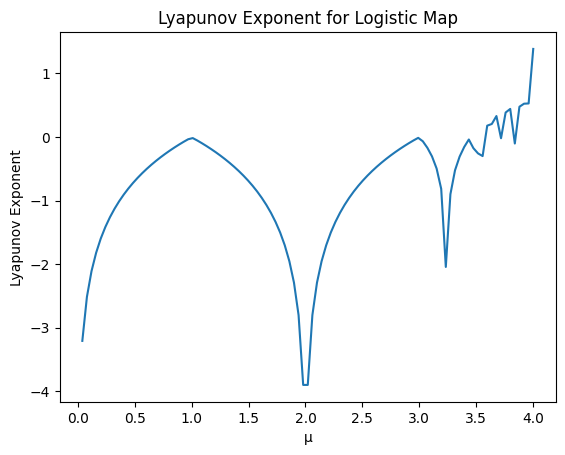

In [16]:
plt.plot(mu_values, lyapunov_exponents)
plt.xlabel('μ')
plt.ylabel('Lyapunov Exponent')
plt.title('Lyapunov Exponent for Logistic Map')
plt.show()

Q4 - B.1: lyapunov for q2

In [17]:
w_0 = 1.0
alpha = 0.2
f = 0.52
w = 0.666

def chaotic_system(X, t, w_0, alpha, f, w):
    theta, y = X
    dtheta_dt = y
    dy_dt = -(w_0)**2 * np.sin(theta) - alpha * y + f * np.cos(w * t)
    return [dtheta_dt, dy_dt]

theta_0 = 0.1
y_0 = 0.0

t_span = [0, 1000]
num_steps = 10000

t = np.linspace(t_span[0], t_span[1], num_steps)
X = odeint(chaotic_system, [theta_0, y_0], t, args=(w_0, alpha, f, w))
theta, y = X.T

theta_0_pert = theta_0 + 1e-6
y_0_pert = y_0 + 1e-6

X_pert = odeint(chaotic_system, [theta_0_pert, y_0_pert], t, args=(w_0, alpha, f, w))
theta_pert, y_pert = X_pert.T

distance = np.sqrt((theta - theta_pert)**2 + (y - y_pert)**2)

lyapunov_exp = np.mean(np.log(distance[1:] / distance[:-1])) / (t[1] - t[0])

print(f"Lyapunov exponent: {lyapunov_exp:.6f}")

Lyapunov exponent: -0.000985


Q4 - B.2: lyapunov for q3

In [18]:
def chaotic_system(X, t):
    x, y, z = X
    dx_dt = 10 * (y - x)
    dy_dt = -x * z + 28 * x - y
    dz_dt = x * y - (8 / 3) * z
    return [dx_dt, dy_dt, dz_dt]

x_0 = 1.0
y_0 = 1.0
z_0 = 1.0

t_span = [0, 100]
num_steps = 10000

t = np.linspace(t_span[0], t_span[1], num_steps)
X = odeint(chaotic_system, [x_0, y_0, z_0], t)
x, y, z = X.T

x_0_pert = x_0 + 1e-6
y_0_pert = y_0 + 1e-6
z_0_pert = z_0 + 1e-6

X_pert = odeint(chaotic_system, [x_0_pert, y_0_pert, z_0_pert], t)
x_pert, y_pert, z_pert = X_pert.T

distance = np.sqrt((x - x_pert)**2 + (y - y_pert)**2 + (z - z_pert)**2)

lyapunov_exp = np.mean(np.log(distance[1:] / distance[:-1])) / (t[1] - t[0])

print(f"Lyapunov exponent: {lyapunov_exp:.6f}")

Lyapunov exponent: 0.159317


Q5

In [19]:
def compute_lyapunov_exponent(time_series):
    n = len(time_series)
    epsilon = 1e-8  
    perturbed_series = time_series + epsilon

    sum_log_divergence = 0.0

    for i in range(n):
        
        distance = np.abs(time_series[i] - perturbed_series[i])

        
        sum_log_divergence += np.log(distance / epsilon)

    
    lyapunov_exponent = sum_log_divergence / n

    return lyapunov_exponent

In [22]:
time_series_1 = np.loadtxt('C:\\Users\\user\\OneDrive\\Desktop\\software\\0.200.txt')
time_series_2 = np.loadtxt('C:\\Users\\user\\OneDrive\\Desktop\\software\\0.900.txt')
time_series_3 = np.loadtxt('C:\\Users\\user\\OneDrive\\Desktop\\software\\logistic_map4.txt')
time_series_4 = np.loadtxt('C:\\Users\\user\\OneDrive\\Desktop\\software\\position.txt')
time_series_5 = np.loadtxt('C:\\Users\\user\\OneDrive\\Desktop\\software\\position2.txt')
time_series_6 = np.loadtxt('C:\\Users\\user\\OneDrive\\Desktop\\software\\velocity.txt')

In [25]:
lyapunov_exp_1 = compute_lyapunov_exponent(time_series_1)
lyapunov_exp_2 = compute_lyapunov_exponent(time_series_2)
lyapunov_exp_3 = compute_lyapunov_exponent(time_series_3)
lyapunov_exp_4 = compute_lyapunov_exponent(time_series_4)
lyapunov_exp_5 = compute_lyapunov_exponent(time_series_5)
lyapunov_exp_6 = compute_lyapunov_exponent(time_series_6)


print("Lyapunov Exponent 1:", lyapunov_exp_1)
print("Lyapunov Exponent 2:", lyapunov_exp_2)
print("Lyapunov Exponent 3:", lyapunov_exp_3)
print("Lyapunov Exponent 4:", lyapunov_exp_4)
print("Lyapunov Exponent 5:", lyapunov_exp_5)
print("Lyapunov Exponent 6:", lyapunov_exp_6)

Lyapunov Exponent 1: [ 5.79767033e-05 -5.99322245e-10]
Lyapunov Exponent 2: [ 5.79767033e-05 -5.81152582e-10]
Lyapunov Exponent 3: [-1.71578983e-04  2.35598634e-09]
Lyapunov Exponent 4: [6.56151248e-07 7.40512912e-08]
Lyapunov Exponent 5: [6.56151248e-07 1.14403623e-09]
Lyapunov Exponent 6: [ 6.56151248e-07 -1.27109323e-09]
